# 1. Introduction


## 1.1 Author

---
Speaker: Felippe Andrade
Your Position: Budding Data Scientist

---

I've been assigned the following task:
"There is a dataset containing fluctuations that took place in Bovespa (bovespa.csv).
Your job is to perform Exploratory Data Analysis on this dataset and showcase graphs that depict the quality and traits of the data."

---

## 1.2 Imports

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    import warnings
except ModuleNotFoundError:
    !pip install warnings

In [66]:
sns.set_style("whitegrid")

In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning)

# 2. Exploratory Analysis


In [67]:
df = pd.read_excel("data/bovespa.xlsx")

In [68]:
df

,date,price,minimum,maximum,variation,variation_percentage,volume
0,2020-09-25,96999.38,95631.74,97011.80,-12.69,-0.01,7351088
1,2020-09-24,97012.07,95652.56,97954.63,1277.25,1.33,9331043
2,2020-09-23,95734.82,95728.13,97388.94,-1558.72,-1.60,8830686
3,2020-09-22,97293.54,96390.28,97684.16,302.82,0.31,7281307
4,2020-09-21,96990.72,95820.34,98282.75,-1298.99,-1.32,9738004
...,...,...,...,...,...,...,...
122,2020-04-02,72253.46,70956.84,73861.00,1286.76,1.81,10540157
123,2020-04-01,70966.70,69568.56,73010.78,-2053.06,-2.81,10093470
124,2020-03-31,73019.76,72385.14,75511.03,-1619.72,-2.17,11141469
125,2020-03-30,74639.48,73184.22,75429.74,1210.70,1.65,9032163


| Column               | Description                                                                                   |
|----------------------|-----------------------------------------------------------------------------------------------|
| date                 | This column represents the date of each data point                                            |
| price                | This float64 column represent a price value for each corresponding date                       |
| minimum              | This float64 column represent the minimum price value for a given day                         |
| maximum              | This float64 column represent the maximum price value for a given day                         |
| variation            | This float64 column represent the day-to-day price change                                     |
| variation_percentage | This float64 column is likely the percentage change in price                                  |
| volume               | This int64 column represents the number of contracts traded in a market during a given period |


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  127 non-null    datetime64[ns]
 1   price                 127 non-null    float64       
 2   minimum               127 non-null    float64       
 3   maximum               127 non-null    float64       
 4   variation             127 non-null    float64       
 5   variation_percentage  127 non-null    float64       
 6   volume                127 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 7.1 KB


The dataset, verified for accuracy and completeness, lacks an 'open' column typically present in stock exchange data. This will be addressed in the following steps.

# 3. Clean and Processing Data


## 3.1 Before


In [70]:
df

,date,price,minimum,maximum,variation,variation_percentage,volume
0,2020-09-25,96999.38,95631.74,97011.80,-12.69,-0.01,7351088
1,2020-09-24,97012.07,95652.56,97954.63,1277.25,1.33,9331043
2,2020-09-23,95734.82,95728.13,97388.94,-1558.72,-1.60,8830686
3,2020-09-22,97293.54,96390.28,97684.16,302.82,0.31,7281307
4,2020-09-21,96990.72,95820.34,98282.75,-1298.99,-1.32,9738004
...,...,...,...,...,...,...,...
122,2020-04-02,72253.46,70956.84,73861.00,1286.76,1.81,10540157
123,2020-04-01,70966.70,69568.56,73010.78,-2053.06,-2.81,10093470
124,2020-03-31,73019.76,72385.14,75511.03,-1619.72,-2.17,11141469
125,2020-03-30,74639.48,73184.22,75429.74,1210.70,1.65,9032163


In [71]:
df["month"] = df["date"].dt.to_period('M')
df['month'] = df['month'].apply(lambda date: date.strftime('%Y-%m'))

We are creating the column _month_ to group dates by month.

In [72]:
df = df[df['date'].dt.month != 3]

Remove the sales data from March as it is insufficient for analysis due to the dataset covering a limited period of only 3 days.

In [ ]:
def calculate_iqr(data_frame: pd.DataFrame) -> pd.Series:
    """
    Calculate the Interquartile Range (IQR) for a given DataFrame.

    :param data_frame: A pandas DataFrame containing the data.
    :return: A Pandas Series representing the IQR.
    """
    q1 = data_frame.quantile(0.25)
    q3 = data_frame.quantile(0.75)
    return q3 - q1

In [73]:
def remove_outliers(*, data_frame: pd.DataFrame) -> pd.DataFrame:
    """
    Remove outliers from a pandas DataFrame.

    :param data_frame: The input DataFrame.
    :return: The DataFrame with outliers was removed.
    """
    iqr_multiplier = 1.5
    numeric_cols_df = data_frame.select_dtypes(include=np.number)

    iqr = calculate_iqr(numeric_cols_df)
    lower_threshold = numeric_cols_df.quantile(0.25) - iqr_multiplier * iqr
    upper_threshold = numeric_cols_df.quantile(0.75) + iqr_multiplier * iqr

    data_frame[numeric_cols_df.columns] = numeric_cols_df.clip(lower_threshold, upper_threshold, axis=1)
    return data_frame

In [74]:
df = remove_outliers(data_frame=df.copy())

In [75]:
df['day_of_week'] = df['date'].dt.day_name()

This will create a new _day_of_week_ column in the DataFrame with the name of each day corresponding to each date in the _date_ column.

## 3.2 After

In [76]:
df

,date,price,minimum,maximum,variation,variation_percentage,volume,month,day_of_week
0,2020-09-25,96999.38,95631.74,97011.80,-12.69,-0.010,7351088.0,2020-09,Friday
1,2020-09-24,97012.07,95652.56,97954.63,1277.25,1.330,9331043.0,2020-09,Thursday
2,2020-09-23,95734.82,95728.13,97388.94,-1558.72,-1.600,8830686.0,2020-09,Wednesday
3,2020-09-22,97293.54,96390.28,97684.16,302.82,0.310,7281307.0,2020-09,Tuesday
4,2020-09-21,96990.72,95820.34,98282.75,-1298.99,-1.320,9738004.0,2020-09,Monday
...,...,...,...,...,...,...,...,...,...
119,2020-04-07,76358.09,74078.01,79855.48,2285.11,3.080,11286506.0,2020-04,Tuesday
120,2020-04-06,74072.98,69555.61,75259.70,4535.42,5.545,9685375.0,2020-04,Monday
121,2020-04-03,69537.56,67802.47,72241.09,-2715.90,-3.760,10411316.0,2020-04,Friday
122,2020-04-02,72253.46,70956.84,73861.00,1286.76,1.810,10540157.0,2020-04,Thursday


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 124 entries, 0 to 123
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  124 non-null    datetime64[ns]
 1   price                 124 non-null    float64       
 2   minimum               124 non-null    float64       
 3   maximum               124 non-null    float64       
 4   variation             124 non-null    float64       
 5   variation_percentage  124 non-null    float64       
 6   volume                124 non-null    float64       
 7   month                 124 non-null    object        
 8   day_of_week           124 non-null    object        
dtypes: datetime64[ns](1), float64(6), object(2)
memory usage: 9.7+ KB


# 4. Visual Analysis


In [78]:
def calc_metrics(*, y_column: str, y_label: str, data_frame: pd.DataFrame = df) -> None:
    """
    Calculate metrics for analyzing a given DataFrame.

    :param y_column: The column containing the data to analyze.
    :param y_label: The label for the y-axis in the plot.
    :param data_frame: The DataFrame to analyze. Defaults to 'df'.
    """
    average_y = np.mean(data_frame[y_column])
    percentile_25, percentile_50, percentile_75 = np.percentile(data_frame[y_column], [25, 50, 75])

    plt.axhline(y=average_y, color='red', linestyle='-', label=f'Average {y_label}')
    plt.axhline(y=percentile_25, color='yellow', linestyle='-', label='25th percentile')
    plt.axhline(y=percentile_50, color='purple', linestyle='-', label='50th percentile (median)')
    plt.axhline(y=percentile_75, color='green', linestyle='-', label='75th percentile')
    plt.legend()

## 4.1. Line Plot

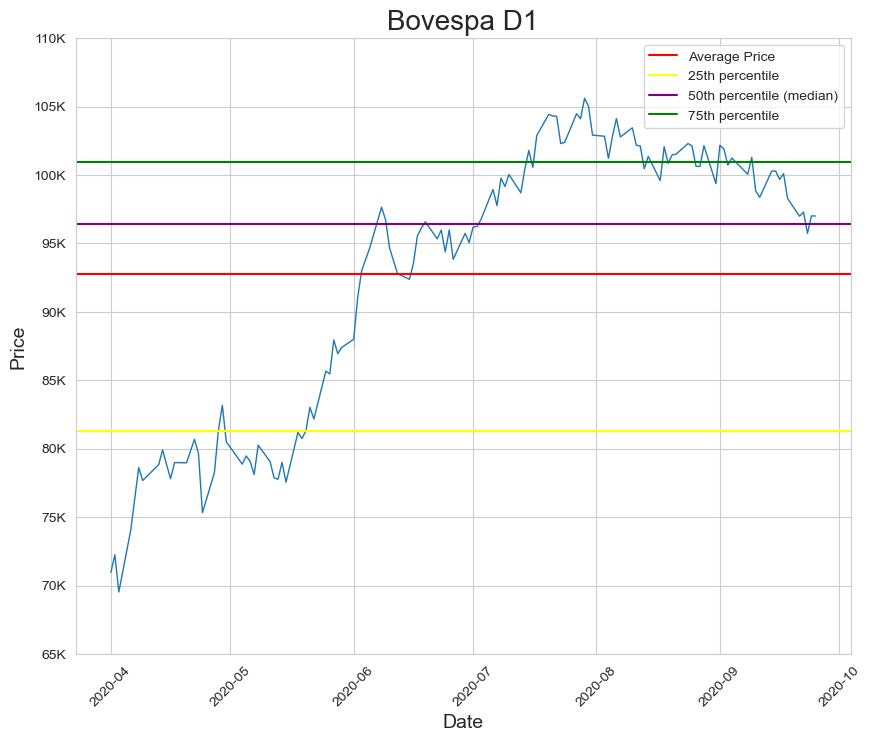

In [79]:
plt.figure(figsize=(10, 8))

sns.lineplot(x="date", y="price", data=df, legend=False, linewidth=1)

plt.title("Bovespa D1", fontsize=20)
plt.xlabel("Date", fontsize=14)
plt.ylabel("Price", fontsize=14)

calc_metrics(y_column="price", y_label="Price")

plt.xticks(rotation=45)
ticks = range(65_000, 110_001, 5_000)
plt.yticks(
    ticks=ticks,
    labels=[f"{i // 1000}K" for i in ticks]
)
plt.show()

This chart displays the price of Bovespa over a 124-day period.
The **median price is 100K**, indicating that half of the values are below and above this price level.
The **25th percentile is at 90K**, while the **75th percentile is at 105K**,
suggesting that **50% of the values range from 90K to 105K**.
The **minimum price is 65K, and the maximum price is 110K**, which might indicate the presence of outliers.
The chart indicates that the stocks experienced a volatile phase during this period,
characterized by price swings and market uncertainty or instability.

## 4.2 Box Plots


In [80]:
def set_boxplot(*, y_label: str, data_frame: pd.DataFrame) -> None:
    """
    Set up and display a boxplot chart.

    :param y_label: The label for the y-axis.
    :param data_frame: The pandas DataFrame containing the data.
    """
    plt.figure(figsize=(10, 8))
    y_column = y_label.lower().replace(' ', '_')

    sns.boxplot(x="month", y=y_column, data=data_frame.sort_values('month'), palette="Spectral")
    plt.title(y_label, fontsize=20)
    plt.xlabel('Month', fontsize=14)
    plt.ylabel(y_label, fontsize=14)

    calc_metrics(y_column=y_column, y_label=y_label)

    plt.xticks(
        ticks=range(0, 6, 1),
        labels=['Apr 2020', 'May 2020', 'Jun 2020', 'Jul 2020', 'Aug 2020', 'Sep 2020']
    )

### 4.2.1 Volume


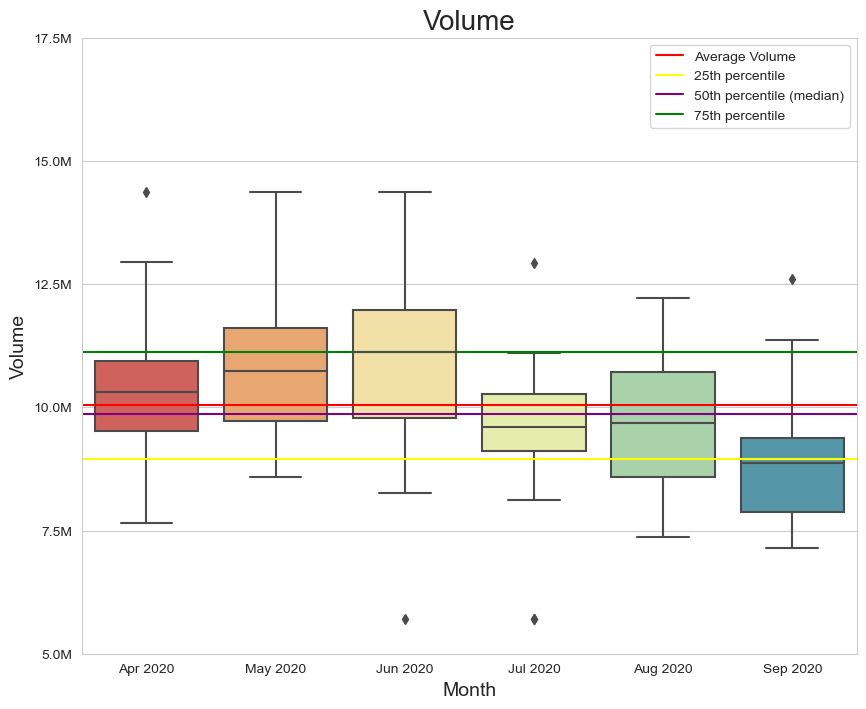

In [81]:
set_boxplot(y_label="Volume", data_frame=df)
ticks = range(5_000_000, 17_500_001, 2_500_000)
plt.yticks(
    ticks=ticks,
    labels=[f"{i / 1_000_000}M" for i in ticks],
)
plt.show()

The graph suggests a gradual decrease in transaction volume, leading to several possible interpretations:

1. **Waning Stock Market Interest**: A dip in trading volume could imply dwindling investor interest, possibly resulting from shifts in market sentiment.
2. **Seasonal Pattern**: Trading volume could dip during certain periods of the year, suggesting a seasonal norm.
3. **Market Correction**: A volume decrease might indicate a market correction—an adjustment of asset prices to their perceived accurate values.
4. **Economic Influences**: A decrease in transaction volume might suggest macroeconomic factors at play, such as a slowing economy or recession. 

### 4.2.2 Price


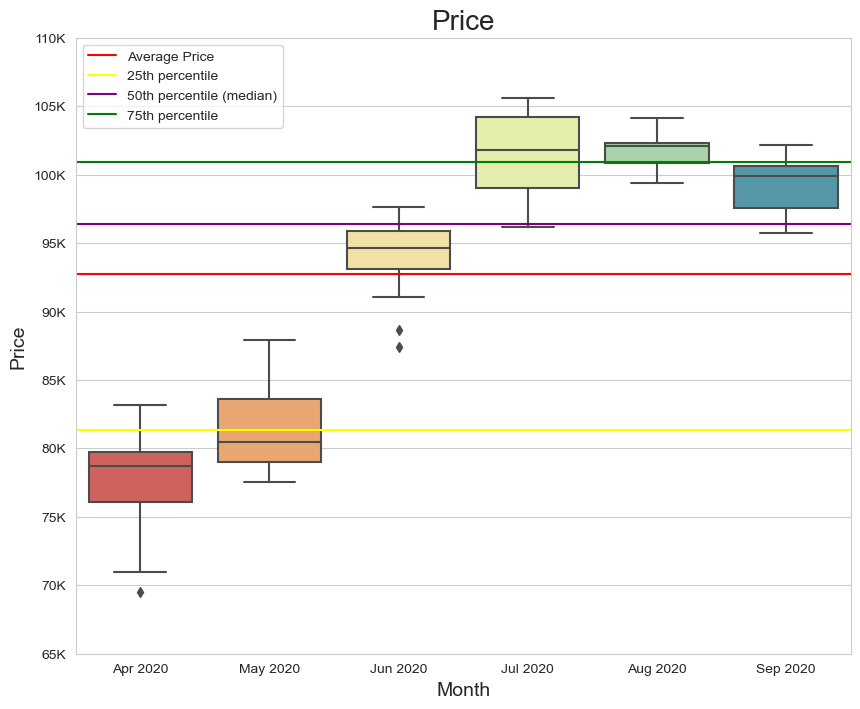

In [82]:
set_boxplot(y_label="Price", data_frame=df)
ticks = list(range(65_000, 110_001, 5_000))
plt.yticks(
    ticks=ticks,
    labels=[f'{i // 1000}K' for i in ticks]
)
plt.show()

The graph reveals that prices underwent considerable fluctuations in the period from April 2020 to September 2020.

- **Volatility**: The notable ups and downs displayed on the price chart suggest high volatility in this stock. Such turbulence could mean market uncertainty or instability.
- **Price Trends**: During this period, the share price showed a downward trend from April to June, reaching a minimum of 80K in June. However, in the following months, the price recovered and rose steadily, reaching a maximum of 110K in September.
- **Outliers**: The minimum price of 65K and the maximum price of 110K indicate the presence of potential outliers. Outliers can be the result of market manipulation, unexpected news, or other factors that influence the market.

### 4.2.3 Best days of the week

In [83]:
days = {'Monday': 0, 'Tuesday': 1, 'Wednesday': 2, 'Thursday': 3, 'Friday': 4}

returns_by_week_day = pd.DataFrame(round(df['variation_percentage'].groupby(df['day_of_week']).sum(), 2)).assign(
    pos_neg=lambda data_frame: data_frame['variation_percentage'] > 0,
    day_number=lambda data_frame: data_frame.index.map(days)).sort_values('day_number')

1. The _variation_percentage_ is selected from the _df_ DataFrame:
`df['variation_percentage']` 
2. The data is then grouped by the _day_of_week_ column, and the _variation_percentage_ values for each group (day of the week) are summed up:
`df['variation_percentage'].groupby(df['day_of_week']).sum()`
3. These sums are then rounded off to the nearest two decimal points:
`round(df['variation_percentage'].groupby(df['day_of_week']).sum(), 2)` 
4. The resultant data, after all these operations, is then converted into a DataFrame:
`pd.DataFrame(round(df['variation_percentage'].groupby(df['day_of_week']).sum(), 2))` 
5. Upon creation of this DataFrame, two new columns are added using the assign method:
_pos_neg_: This is a column of Boolean values determined by if the _variation_percentage_ column in the new DataFrame is greater than zero or not.
_day_number_: The index from the new DataFrame is mapped using the _days_ mapping presumably established earlier in the code, which maps the days of the week to corresponding numeric values.
`pd.DataFrame(round(df['variation_percentage'].groupby(df['day_of_week']).sum(), 2)).assign(pos_neg=lambda dataframe: dataframe['variation_percentage'] > 0, day_number=lambda dataframe: dataframe.index.map(days))`
6. In the end, the DataFrame is re-ordered by sorting, according to the _day_number_ column:
`pd.DataFrame(round(df['variation_percentage'].groupby(df['day_of_week']).sum(), 2)).assign(pos_neg=lambda dataframe: dataframe['variation_percentage'] > 0, day_number=lambda dataframe: dataframe.index.map(days)).sort_values('day_number')`
Finally, we've got the _returns_by_week_day_ DataFrame. It contains the accumulated and rounded variation percentages for each weekday, along with flags indicating whether these sums are positive or not, and their corresponding numeric day values. The DataFrame is also nicely sorted in the order of the weekdays.

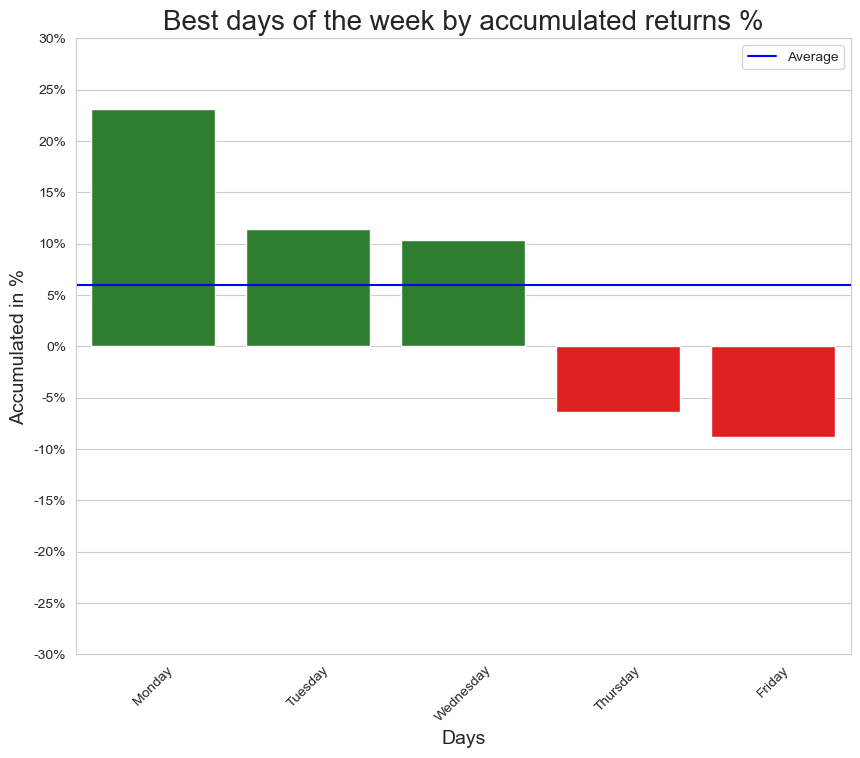

In [84]:
plt.figure(figsize=(10, 8))

sns.barplot(x=returns_by_week_day.index, y='variation_percentage', data=returns_by_week_day,
            palette=returns_by_week_day['pos_neg'].map({True: 'forestgreen', False: 'red'}))

mean = np.mean(returns_by_week_day["variation_percentage"])
plt.axhline(y=mean, color='blue', linestyle='-', label=f'Average')

plt.legend()

plt.title('Best days of the week by accumulated returns %', size=20)
plt.xlabel('Days', size=14)
ticks = list(range(-30, 31, 5))
plt.yticks(
    ticks=ticks,
    labels=[f'{i}%' for i in ticks]
)
plt.ylabel('Accumulated in %', size=14)
plt.xticks(rotation=45)
plt.show()

* Based on the provided data, Monday surfaces as the most profitable day of the week with an average return of 23.10%. Following closely is Tuesday, yielding an average return of 11.45%. Wednesday is the third in the standing with gains averaging 10.40%. 
* Despite Thursday's negative average return of -6.43%, it still ranks fourth in terms of weekly profitability. The least beneficial day is Friday, showing an average downturn of -8.82%. 
* The overall weekly gain averages at 5.93%, indicating a potential for positive return for an investor through the week, notwithstanding the dips on Thursday and Friday.
* To optimize returns, trades at the beginning of the week, particularly on Mondays and Tuesdays, could be more fruitful. However, individual results could deviate and past performance shouldn't be seen as a guarantee of future outcomes.

# 5. Conclusion

Based on the analysis of the three charts and data on lucrative days of the week, the following conclusions emerge:

- **Volume Trend**: The exchange's trading volume dwindled from April to September 2020, possibly hinting at waning interest or a market correction.
- **Price Fluctuation**: The stock price underwent substantial shifts, indicating volatility and possible unpredictability in the market.
- **Days of the Week**: Monday and Tuesday outperformed other weekdays, suggesting investors might gain from concentrating trades on these days.